# 02 - Collisions: EDA and cleaning (stage 2)

**Owner:** Ahmed | **Dataset:** NYC Motor Vehicle Collisions - Crashes (`h9gi-nx95`) | **Output:** `data/collisions_step2.csv.gz`

**Story question:** do the neighborhoods where NYC builds the most also become the most dangerous to walk, bike and drive in? This notebook only prepares the **transportation** side. Everything here describes *correlation-ready* data; this notebook makes no claim about causation, only about data quality.

### How to run
1. Create a venv and install: `pip install -r requirements.txt`
2. Open this notebook in VS Code (Jupyter extension), choose the venv kernel, **Restart Kernel and Run All**.
3. The first run downloads about 450k rows from the NYC Open Data API (about 1-2 minutes) into `data/collisions_raw.csv`. Later runs reuse that file. `data/` is git-ignored.
4. This notebook always starts from `data/collisions_raw.csv`. Yassin's stage 1 (`collisions_step1.csv.gz`) is not used here until his branch is merged and its columns are agreed.

### Agreed standards used here
`zip_code` = 5-digit **string**, `year` = integer, grain for the later join = one row per `zip_code` x `year`. Scope = crashes from 2022-01-01 onward.

In [1]:
from pathlib import Path
import io

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

DATA_DIR = Path("data")            # relative path only; data/ is git-ignored
DATA_DIR.mkdir(exist_ok=True)
RAW = DATA_DIR / "collisions_raw.csv"
STEP2 = DATA_DIR / "collisions_step2.csv.gz"

## 1. Load the data

**Dataset links:** [Motor Vehicle Collisions - Crashes (h9gi-nx95)](https://data.cityofnewyork.us/d/h9gi-nx95) | housing partner dataset: [DOB NOW Job Filings (w9ak-ipjd)](https://data.cityofnewyork.us/d/w9ak-ipjd)

**Sampling choice (justification):** we do *not* take a random sample. We load **every crash since 2022-01-01** through a SoQL date filter. A date rule is not a sample, so it introduces no random-sampling bias, and about 450k rows is small enough to hold in memory. It also matches the housing dataset's scope (2022 onward), which is what makes a ZIP x year comparison fair.

**Why paginate:** the API returns only 1,000 rows by default. We request 50,000 per page with `$order=collision_id` so pages are stable (no repeated or skipped rows between requests). `zip_code` is read as a **string** from the start, otherwise pandas turns it into a float (`10001.0`) and leading zeros would be lost.

In [2]:
URL = "https://data.cityofnewyork.us/resource/h9gi-nx95.csv"
PAGE = 50_000

def pull_all():
    """Download every collision since 2022-01-01, page by page."""
    frames, offset = [], 0
    while True:
        params = {"$where": "crash_date >= '2022-01-01T00:00:00'",
                  "$order": "collision_id", "$limit": PAGE, "$offset": offset}
        r = requests.get(URL, params=params, timeout=180)
        r.raise_for_status()
        chunk = pd.read_csv(io.StringIO(r.text), dtype={"zip_code": str, "collision_id": str})
        if chunk.empty:
            break
        frames.append(chunk)
        offset += PAGE
    return pd.concat(frames, ignore_index=True)

if not RAW.exists():
    # Write to a temporary file first and rename only after the full pull succeeded,
    # so an interrupted download can never leave a half-written collisions_raw.csv behind.
    TMP = RAW.with_name(RAW.name + ".tmp")
    pull_all().to_csv(TMP, index=False)
    TMP.replace(RAW)

source = RAW
df = pd.read_csv(source, dtype={"zip_code": str, "collision_id": str})
print("Loaded from:", source)
raw_rows = len(df)
print("shape:", df.shape)

Loaded from: data\collisions_raw.csv
shape: (447156, 29)


## 2. Feasibility check (is this dataset usable for our question?)

The collisions dataset is not clearly named in the data-catalog PDF, so we verify it directly: size, columns, time span, and whether it can join to the housing data.

In [3]:
print("Rows x columns :", df.shape)
dates = pd.to_datetime(df["crash_date"])
print("Date range     :", dates.min().date(), "->", dates.max().date())
print("ZIP present    : {:.1%}".format(df["zip_code"].notna().mean()))
print("Lat/lon present: {:.1%}".format(df["latitude"].notna().mean()))
print("Distinct ZIPs  :", df["zip_code"].nunique())
print()
df.info()

Rows x columns : (447156, 29)


Date range     : 2022-01-01 -> 2026-10-31
ZIP present    : 71.9%
Lat/lon present: 94.5%
Distinct ZIPs  : 230



<class 'pandas.DataFrame'>
RangeIndex: 447156 entries, 0 to 447155
Data columns (total 29 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   crash_date                     447156 non-null  str    
 1   crash_time                     447156 non-null  str    
 2   borough                        345885 non-null  str    
 3   zip_code                       321362 non-null  str    
 4   latitude                       422635 non-null  float64
 5   longitude                      422635 non-null  float64
 6   location                       422635 non-null  str    
 7   on_street_name                 317378 non-null  str    
 8   off_street_name                129774 non-null  str    
 9   cross_street_name              230935 non-null  str    
 10  number_of_persons_injured      447156 non-null  int64  
 11  number_of_persons_killed       447156 non-null  int64  
 12  number_of_pedestrians_injured  447156 non

**Feasibility verdict.**
- **Rows / columns:** about 447k crashes x 29 columns for 2022-01-01 to 2026-10-31 (the extract date), enough for ZIP x year aggregation (228 distinct ZIPs with a valid ZIP).
- **Join key:** the housing data has `postcode`, the collisions data has `zip_code`. There is *no row-level key* (a crash is not a building), so we aggregate both sides to **zip_code x year** and combine the summaries. This is the only honest join available, and it is why the ZIP column quality matters so much in this notebook.
- **Why the pair supports the question:** housing filings tell us *where and when* construction activity happens; collisions give *where and when* people are hurt, with separate pedestrian, cyclist and motorist counts. Both are public, geolocated, and cover the same years.
- **Known risk found already:** ZIP is missing for ~28% of crashes (section 4.5). This is the main limitation of the whole project.

## 3. Exploratory data analysis (before cleaning)

In [4]:
miss = df.isna().mean().sort_values(ascending=False).mul(100).round(1)
print("% missing per column"); print(miss.to_string())

% missing per column
vehicle_type_code_5              99.3
contributing_factor_vehicle_5    99.3
vehicle_type_code_4              97.8
contributing_factor_vehicle_4    97.7
vehicle_type_code_3              91.8
contributing_factor_vehicle_3    91.1
off_street_name                  71.0
cross_street_name                48.4
vehicle_type_code2               34.0
on_street_name                   29.0
zip_code                         28.1
contributing_factor_vehicle_2    23.2
borough                          22.6
location                          5.5
latitude                          5.5
longitude                         5.5
vehicle_type_code1                1.6
contributing_factor_vehicle_1     0.6
crash_date                        0.0
number_of_persons_injured         0.0
crash_time                        0.0
number_of_pedestrians_injured     0.0
number_of_persons_killed          0.0
number_of_motorist_killed         0.0
number_of_motorist_injured        0.0
number_of_pedestrians_killed 

In [5]:
num_cols = [c for c in df.columns if c.startswith("number_of")]
print(df[num_cols].describe().T[["count", "mean", "std", "min", "max"]].round(3))

                                  count   mean    std  min   max
number_of_persons_injured      447156.0  0.563  0.850  0.0  40.0
number_of_persons_killed       447156.0  0.003  0.056  0.0   5.0
number_of_pedestrians_injured  447156.0  0.099  0.315  0.0  19.0
number_of_pedestrians_killed   447156.0  0.001  0.037  0.0   4.0
number_of_cyclist_injured      447156.0  0.054  0.229  0.0   3.0
number_of_cyclist_killed       447156.0  0.000  0.014  0.0   1.0
number_of_motorist_injured     447156.0  0.382  0.827  0.0  40.0
number_of_motorist_killed      447156.0  0.001  0.036  0.0   5.0


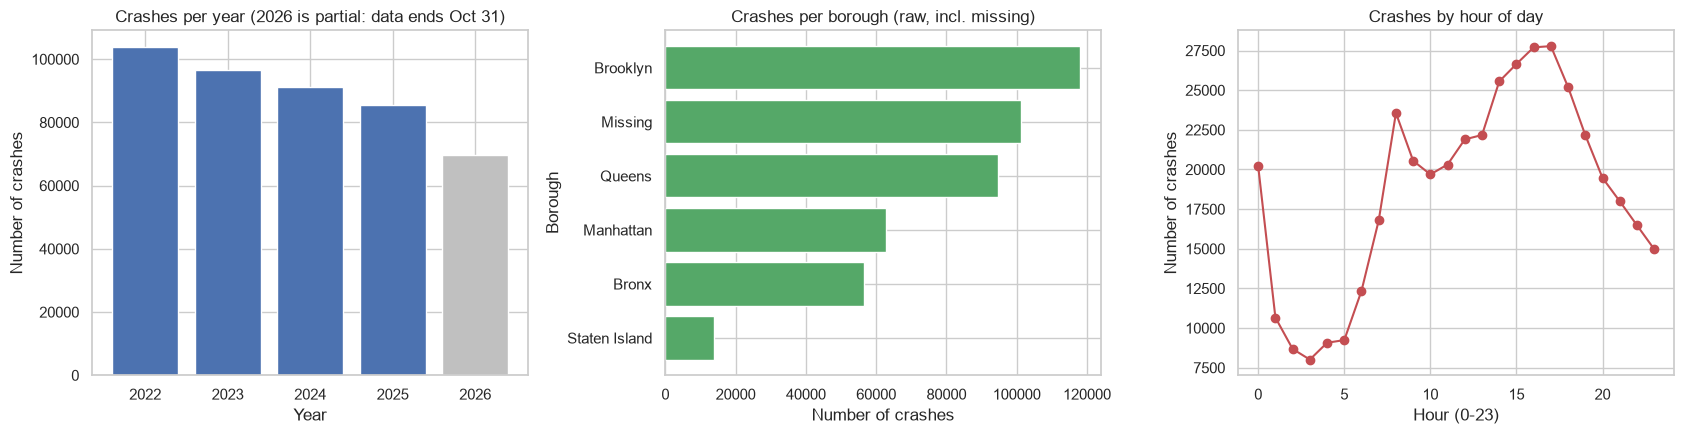

In [6]:
df["_date"] = pd.to_datetime(df["crash_date"])
df["_year"] = df["_date"].dt.year
df["_hour"] = df["crash_time"].str.split(":").str[0].astype(int)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

yearly = df["_year"].value_counts().sort_index()
colors = ["#4c72b0"] * (len(yearly) - 1) + ["#c0c0c0"]          # grey = partial year
axes[0].bar(yearly.index.astype(str), yearly.values, color=colors)
axes[0].set(title="Crashes per year (2026 is partial: data ends Oct 31)", xlabel="Year", ylabel="Number of crashes")

bor = df["borough"].value_counts(dropna=False)
bor.index = bor.index.fillna("Missing").str.title()      # display labels in Title Case, same as housing
axes[1].barh(bor.index[::-1], bor.values[::-1], color="#55a868")
axes[1].set(title="Crashes per borough (raw, incl. missing)", xlabel="Number of crashes", ylabel="Borough")

hour = df["_hour"].value_counts().sort_index()
axes[2].plot(hour.index, hour.values, marker="o", color="#c44e52")
axes[2].set(title="Crashes by hour of day", xlabel="Hour (0-23)", ylabel="Number of crashes")
plt.tight_layout(); plt.show()

In [7]:
peak_hour, quiet_hour = hour.idxmax(), hour.idxmin()
print(f"peak hour  : {peak_hour:02d}:00 with {hour.max():,} crashes")
print(f"quietest   : {quiet_hour:02d}:00 with {hour.min():,} crashes")
print(f"hour 00:00 : {hour[0]:,} crashes vs {hour[1]:,} at 01:00 and {hour[2]:,} at 02:00")
print(f"no borough : {int(df['borough'].isna().sum()):,} crashes ({df['borough'].isna().mean():.1%})")

peak hour  : 17:00 with 27,778 crashes
quietest   : 03:00 with 8,012 crashes
hour 00:00 : 20,207 crashes vs 10,661 at 01:00 and 8,684 at 02:00
no borough : 101,271 crashes (22.6%)


**What the plots show.** Crashes fall every full year (2022 -> 2025) and 2026 is grey because it only has ten months. The raw borough chart has a big **Missing** bar: 101,271 crashes (22.6%) have no borough at all, which is the first sign that location fields are incomplete. Crashes peak at 17:00 (27,778 crashes) and are lowest at 03:00 (8,012). Hour 00:00 (20,207 crashes) is much higher than 01:00 or 02:00; we have not checked why, one possible reason is that records without a known time are entered as midnight, so treat the midnight hour with caution. Because 2026 is partial, **never compare 2026 totals with full years**; use rates per month or flag it as partial in every chart.

## 4. Cleaning

Each step states **what** we did, **how many rows** it touched, **why**, and the **alternative we rejected**. Cleaning is done on a copy; the raw file is never modified.

In [8]:
clean = df.drop(columns=["_date", "_year", "_hour"]).copy()
log = []          # cleaning log: (step, rows affected, decision)
def record(step, n, decision):
    log.append({"step": step, "rows_affected": n, "decision": decision})

### 4.1 Duplicates on `collision_id`
`collision_id` is the official unique crash identifier, so the same id twice means the same crash was exported twice. We check both the id and whole-row duplicates.

In [9]:
dup_id = clean["collision_id"].duplicated().sum()
dup_row = clean.duplicated().sum()
print("duplicate collision_id:", dup_id, "| fully duplicated rows:", dup_row)
clean = clean.drop_duplicates(subset="collision_id", keep="first")
record("duplicates on collision_id", int(dup_id), "drop_duplicates (keep first); 0 found in this extract")

duplicate collision_id: 0 | fully duplicated rows: 0


**Decision:** 0 duplicates found, so nothing is dropped. We still keep the `drop_duplicates` line so the notebook stays correct if the API data changes. *Rejected alternative:* skipping the check because the source is "official" - an unchecked assumption would double count crashes in the ZIP totals.

### 4.2 Data types
- `crash_date` is text like `2022-01-01T00:00:00.000` -> convert to datetime; the time part is always midnight, the real time is in `crash_time`.
- `crash_time` is text `H:MM` -> extract an integer `hour` (needed for hour-of-day analysis).
- Injury and killed columns -> compact integers (`int16`); counts can never be fractional or negative.
- `zip_code` stays a **string**; `collision_id` stays a string (an identifier, not a quantity).
- New columns `year`, `month`, `hour` are integers. `year` is the join key shared with the housing data.

In [10]:
clean["crash_date"] = pd.to_datetime(clean["crash_date"]).dt.normalize()
clean["year"] = clean["crash_date"].dt.year.astype("int16")
clean["month"] = clean["crash_date"].dt.month.astype("int8")
clean["hour"] = clean["crash_time"].str.split(":").str[0].astype("int8")
clean[num_cols] = clean[num_cols].astype("int16")

assert (clean[num_cols] >= 0).all().all(), "negative count found"
print("negative counts: 0 | date range:", clean["crash_date"].min().date(), "->", clean["crash_date"].max().date())
print(clean[["crash_date", "year", "month", "hour"] + num_cols[:2]].dtypes.to_string())
record("dtype conversion", len(clean), "dates -> datetime, counts -> int16, added year/month/hour")

negative counts: 0 | date range: 2022-01-01 -> 2026-10-31
crash_date                   datetime64[us]
year                                  int16
month                                  int8
hour                                   int8
number_of_persons_injured             int16
number_of_persons_killed              int16


**Partial years.** The latest crash is on 2026-10-31, so **2026 covers 10 months only**. We keep 2026 (dropping it would throw away the newest data) but we add an `is_partial_year` flag so every downstream chart can mark or exclude it. *Rejected alternative:* annualising 2026 (x 1.2) - that invents data and assumes crashes are evenly spread over the year.

In [11]:
last_date = clean["crash_date"].max()
clean["is_partial_year"] = clean["year"] == last_date.year
print("Partial-year rows (2026):", int(clean["is_partial_year"].sum()))

Partial-year rows (2026): 69786


### 4.3 Borough: standardize text
The source writes boroughs in upper case with no spelling variants (BROOKLYN, QUEENS, MANHATTAN, BRONX, STATEN ISLAND). The housing dataset uses Title Case ("Brooklyn"), and the website's filters and search must match across both datasets, so we strip whitespace and convert to **Title Case**: Bronx, Brooklyn, Manhattan, Queens, Staten Island. **No borough is invented**: 101,271 rows are empty and stay empty, and no unknown or invalid value is ever mapped to a borough. We check that every ZIP maps to one borough (consistency) in 4.5.

In [12]:
clean["borough"] = clean["borough"].str.strip().str.title()
print(clean["borough"].value_counts(dropna=False).to_string())

borough
Brooklyn         118075
NaN              101271
Queens            94570
Manhattan         62800
Bronx             56584
Staten Island     13856


### 4.4 Contributing factors and vehicle types: standardize text
These columns are free text. We strip and collapse whitespace so the same factor is not counted under two spellings. We deliberately do **not** change the case: the count of distinct values is identical before and after (64 -> 64), so the source already uses one consistent spelling per factor. We **keep** "Unspecified" and "Does Not Apply" as real source values (they carry information: the officer recorded no cause), but the join notebook should exclude them when it computes the *top contributing factor* per ZIP-year, otherwise "Unspecified" would win everywhere.

In [13]:
factor_cols = [f"contributing_factor_vehicle_{i}" for i in range(1, 6)]
vehicle_cols = ["vehicle_type_code1", "vehicle_type_code2", "vehicle_type_code_3", "vehicle_type_code_4", "vehicle_type_code_5"]

before = clean["contributing_factor_vehicle_1"].nunique()
for c in factor_cols + vehicle_cols:
    clean[c] = clean[c].str.strip().str.replace(r"\s+", " ", regex=True)
after = clean["contributing_factor_vehicle_1"].nunique()
print(f"distinct factor_1 values: {before} -> {after}")
print(clean["contributing_factor_vehicle_1"].value_counts().head(12).to_string())
print("\nrarest factor_1 values (look for junk such as numbers):")
print(clean["contributing_factor_vehicle_1"].value_counts().tail(8).to_string())

distinct factor_1 values: 64 -> 64
contributing_factor_vehicle_1
Driver Inattention/Distraction    93031
Does Not Apply                    81358
Unspecified                       76458
Failure to Yield Right-of-Way     27524
Following Too Closely             21666
Passing or Lane Usage Improper    15368
Other Vehicular                   14118
Unsafe Speed                      13404
Passing Too Closely               12438
Backing Unsafely                  11152
Traffic Control Disregarded       10275
Turning Improperly                 8696

rarest factor_1 values (look for junk such as numbers):
contributing_factor_vehicle_1
Other Electronic Device         32
Cell Phone (hands-free)         19
Related to bus stop             18
Windshield Inadequate           18
Shoulders Defective/Improper    17
Drug involvement                14
Texting                         14
Listening/Using Headphones       7


### 4.5 ZIP code (the critical column)

Checks, in order:
1. **Format:** ZIP must be exactly 5 digits as a string. (Checked: all non-missing values already are.)
2. **Validity:** NYC ZIPs run from `10001` to `11697`. Values outside that range are placeholders, not real ZIPs.
3. **Missingness:** how many are missing, and is it random or clustered?
4. **Consistency with borough:** each ZIP should belong to one borough.

In [14]:
z = clean["zip_code"]
bad_fmt = z.notna() & ~z.str.fullmatch(r"\d{5}", na=False)
out_of_range = z.notna() & ~bad_fmt & ~z.between("10001", "11697")
print("not 5 digits:", int(bad_fmt.sum()))
print("5 digits but outside NYC range 10001-11697:", int(out_of_range.sum()), "->", z[out_of_range].value_counts().to_dict())

not 5 digits: 0
5 digits but outside NYC range 10001-11697: 443 -> {'10000': 442, '12345': 1}


**Decision (invalid ZIPs):** `10000` (442 crashes, all tagged Manhattan) and `12345` (1 crash) are placeholders, not real NYC ZIPs - 12345 is the classic dummy value and 10000 is not an assigned ZIP. We set them to **missing** instead of keeping them, because a fake ZIP would create a phantom "neighborhood" in the ZIP x year table. We do not guess the real ZIP. *Rejected alternative:* keeping them because they have a borough - the borough is fine, but the ZIP is wrong.

In [15]:
clean.loc[bad_fmt | out_of_range, "zip_code"] = pd.NA
record("invalid ZIP placeholders", int((bad_fmt | out_of_range).sum()), "set to missing (10000, 12345)")

zip_missing = clean["zip_code"].isna()
print(f"ZIP missing after validation: {zip_missing.sum():,} ({zip_missing.mean():.1%})")
print("...of which lat/lon present :", int((zip_missing & clean['latitude'].notna()).sum()))
print("...of which borough missing :", int((zip_missing & clean['borough'].isna()).sum()))
print("\nZIP missing rate by year:")
print(clean.groupby("year")["zip_code"].apply(lambda s: s.isna().mean()).round(3).to_string())
print("\nZIP missing rate by borough:")
print(clean.groupby("borough", dropna=False)["zip_code"].apply(lambda s: s.isna().mean()).round(3).to_string())

ZIP missing after validation: 126,237 (28.2%)
...of which lat/lon present : 105905
...of which borough missing : 101271

ZIP missing rate by year:
year
2022    0.338
2023    0.320
2024    0.286
2025    0.200
2026    0.243

ZIP missing rate by borough:
borough
Bronx            0.087
Brooklyn         0.053
Manhattan        0.061
Queens           0.096
Staten Island    0.061
NaN              1.000


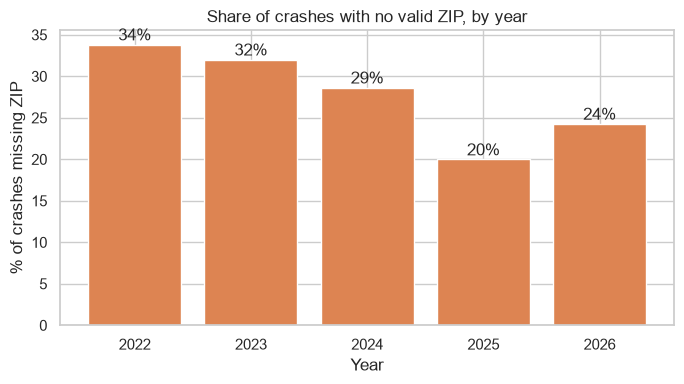

ZIPs that appear under more than one borough: 5


lowest 'majority-borough share' across ZIPs: 0.97


In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
rate = clean.groupby("year")["zip_code"].apply(lambda s: s.isna().mean() * 100)
ax.bar(rate.index.astype(str), rate.values, color="#dd8452")
ax.set(title="Share of crashes with no valid ZIP, by year", xlabel="Year", ylabel="% of crashes missing ZIP")
for x, v in zip(rate.index.astype(str), rate.values):
    ax.text(x, v + 0.5, f"{v:.0f}%", ha="center")
plt.tight_layout(); plt.show()

# consistency: does each ZIP map to exactly one borough?
zb = clean.dropna(subset=["zip_code", "borough"]).groupby("zip_code")["borough"].nunique()
print("ZIPs that appear under more than one borough:", int((zb > 1).sum()))
share = clean.dropna(subset=["zip_code", "borough"]).groupby("zip_code")["borough"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
print("lowest 'majority-borough share' across ZIPs:", share.min().round(3))

**Decision (missing ZIP): KEEP the rows in the cleaned file, drop them only in the ZIP x year aggregate.**
- About **28% of crashes have no ZIP**, and the share is **not random**: it was 34% in 2022 and 20% in 2025, so it differs by year; 101k of those rows also have no borough. A year-by-year drift means ZIP x year crash counts for 2022-2023 are more *under*-counted than for 2025. This is a real limitation to state in the story section.
- Why keep the rows here: they are valid crashes for city-wide totals, hour-of-day charts and the lat/lon map (when coordinates exist). Deleting them would bias those charts for no reason.
- Why drop them later: a crash with no ZIP cannot be assigned to a ZIP x year cell. The aggregation step will therefore exclude them, and the notebook reports how many.
- We add `zip_missing` so the exclusion is explicit and countable.
- **Rejected alternative 1 - impute the most common ZIP or borough:** fabricates locations and would pile crashes onto a few ZIPs.
- **Rejected alternative 2 - recover ZIP from latitude/longitude:** 105k of the missing-ZIP crashes do have coordinates, so a spatial join to ZIP polygons could recover most of them. It is *derivation*, not fabrication, but it needs an extra dataset (ZIP boundaries) and geopandas, and it changes the ZIP definition between the two sides. We list it as an **optional improvement** if the team has time, not as part of the base pipeline.
- ZIP/borough consistency is good but not perfect: 5 ZIPs appear under more than one borough, yet every one has at least 97% of its crashes in a single borough (ZIPs on a borough boundary, e.g. `11237`). That is a handful of labelling differences, not a systematic contradiction, so we leave them as they are; the join uses ZIP, not borough.

In [17]:
clean["zip_missing"] = clean["zip_code"].isna()
record("missing ZIP", int(clean["zip_missing"].sum()), "kept + flagged (zip_missing); excluded only at ZIP-year aggregation")

### 4.6 Latitude / longitude
Checks: missing values, coordinates equal to 0 (a GPS placeholder), and points outside the NYC bounding box (lat 40.4-41.0, lon -74.3 to -73.6).

In [18]:
lat, lon = clean["latitude"], clean["longitude"]
n_missing = int(lat.isna().sum())
n_zero = int(((lat == 0) | (lon == 0)).sum())
outside = lat.notna() & ~((lat == 0) | (lon == 0)) & ~(lat.between(40.4, 41.0) & lon.between(-74.3, -73.6))
print(f"missing lat/lon : {n_missing:,} ({n_missing/len(clean):.1%})")
print(f"exactly 0 (0,0) : {n_zero:,}")
print(f"other outside NYC box: {int(outside.sum())}")
print(clean.loc[lat != 0, ["latitude", "longitude"]].describe().loc[["min", "max"]])

missing lat/lon : 24,521 (5.5%)
exactly 0 (0,0) : 6,282
other outside NYC box: 0
      latitude  longitude
min  40.498947  -74.25496
max  40.912827  -73.70048


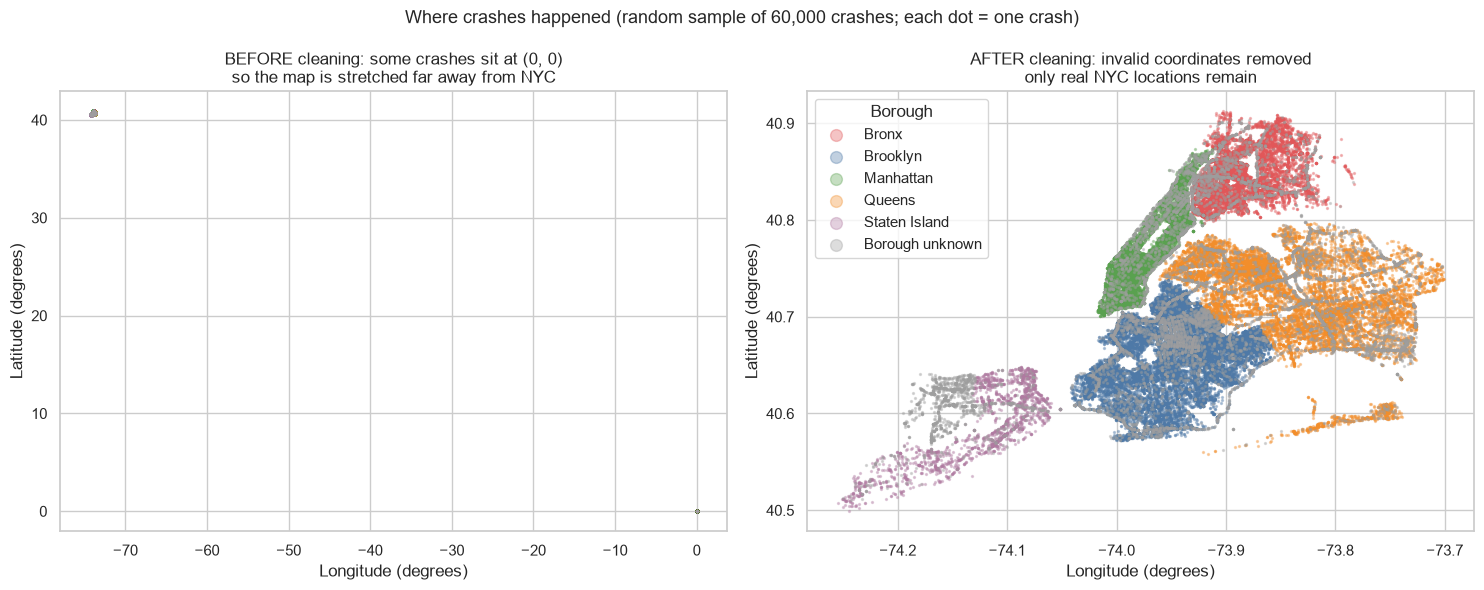

coordinates set to missing: 6282
lat/lon missing AFTER cleaning: 30,803 (6.9%)


In [19]:
BOROUGH_COLORS = {"Bronx": "#e15759", "Brooklyn": "#4e79a7", "Manhattan": "#59a14f",
                  "Queens": "#f28e2b", "Staten Island": "#b07aa1", "Borough unknown": "#9e9e9e"}

def crash_map(ax, data, title):
    """Scatter of crash locations, one colour per borough."""
    b = data["borough"].fillna("Borough unknown")
    for name, color in BOROUGH_COLORS.items():
        pts = data[b == name]
        ax.scatter(pts["longitude"], pts["latitude"], s=2, alpha=0.35, color=color, label=name)
    ax.set(title=title, xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
map_before = clean.dropna(subset=["latitude"]).sample(60_000, random_state=42)
crash_map(axes[0], map_before,"BEFORE cleaning: some crashes sit at (0, 0)\nso the map is stretched far away from NYC")

bad_geo = (lat == 0) | (lon == 0) | outside
clean.loc[bad_geo, ["latitude", "longitude"]] = np.nan
map_after = clean.dropna(subset=["latitude"]).sample(60_000, random_state=42)
crash_map(axes[1], map_after,"AFTER cleaning: invalid coordinates removed\nonly real NYC locations remain")
leg = axes[1].legend(title="Borough", markerscale=6, loc="upper left")
fig.suptitle("Where crashes happened (random sample of 60,000 crashes; each dot = one crash)", fontsize=13)
plt.tight_layout(); plt.show()
record("invalid coordinates (0,0 / outside NYC)", int(bad_geo.sum()), "set to missing")
print("coordinates set to missing:", int(bad_geo.sum()))
n_missing_after = int(clean["latitude"].isna().sum())
print(f"lat/lon missing AFTER cleaning: {n_missing_after:,} ({n_missing_after / len(clean):.1%})")

**How to read the maps:** each dot is one crash placed by its longitude (left-right) and latitude (up-down), coloured by borough (grey = the borough is missing in the data). The left map shows the data *before* cleaning, where crashes with the placeholder location (0, 0) stretch the axes. The right map shows it *after*: the five boroughs form the familiar shape of NYC. A dot in the grey colour just means the crash has coordinates but no borough name.

**Decision:** `(0, 0)` is not a location in NYC (it is in the Atlantic), it is a GPS placeholder, so these coordinates are set to **missing**; the crash row stays because its injury counts, date and ZIP can still be valid. Together with the 24,521 crashes that had no coordinates in the source, 30,803 crashes (6.9%) now have no coordinates. They also stay: coordinates are only needed for the optional map layer, and the base analysis uses ZIP. *Rejected alternative:* dropping all rows without coordinates - that would delete ~31k real crashes from every chart and say nothing about why. We never estimate a coordinate.

### 4.7 Outliers in injury and killed counts
Two kinds of rules are applied: **domain rules** (logically impossible values) and a **statistical rule** (IQR) used for inspection.

In [20]:
inj = num_cols
# domain rule 1: persons total must be >= sum of its parts
inj_gap = clean["number_of_persons_injured"] < clean[["number_of_pedestrians_injured", "number_of_cyclist_injured", "number_of_motorist_injured"]].sum(axis=1)
kil_gap = clean["number_of_persons_killed"] < clean[["number_of_pedestrians_killed", "number_of_cyclist_killed", "number_of_motorist_killed"]].sum(axis=1)
print("persons_injured < sum of parts:", int(inj_gap.sum()), "| persons_killed < sum of parts:", int(kil_gap.sum()))

# statistical rule: IQR on persons injured
q1, q3 = clean["number_of_persons_injured"].quantile([0.25, 0.75])
print("IQR of persons_injured: Q1 =", q1, "Q3 =", q3, "-> upper fence =", q3 + 1.5 * (q3 - q1))
print("share of crashes with >= 1 injured:", round((clean['number_of_persons_injured'] >= 1).mean(), 3))
print("crashes with >= 10 injured:", int((clean['number_of_persons_injured'] >= 10).sum()))
print("crashes with >= 15 injured:", int((clean['number_of_persons_injured'] >= 15).sum()))
print("max persons_injured:", int(clean['number_of_persons_injured'].max()))

persons_injured < sum of parts: 0 | persons_killed < sum of parts: 0
IQR of persons_injured: Q1 = 0.0 Q3 = 1.0 -> upper fence = 2.5
share of crashes with >= 1 injured: 0.42
crashes with >= 10 injured: 98
crashes with >= 15 injured: 24
max persons_injured: 40


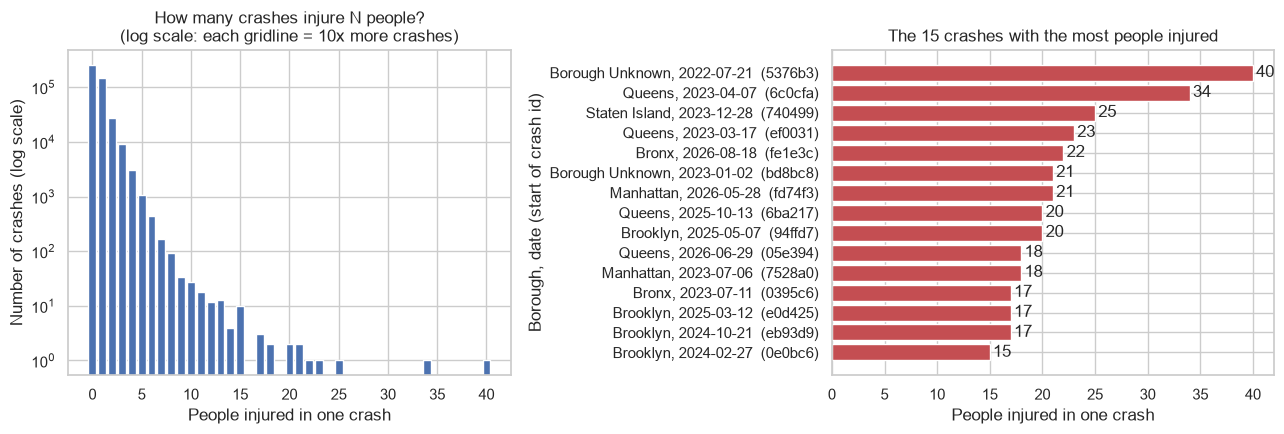

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
vc = clean["number_of_persons_injured"].value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color="#4c72b0"); axes[0].set_yscale("log")
axes[0].set(title="How many crashes injure N people?\n(log scale: each gridline = 10x more crashes)", xlabel="People injured in one crash", ylabel="Number of crashes (log scale)")

big = clean.nlargest(15, "number_of_persons_injured").copy()
big["label"] = (big["borough"].fillna("Borough unknown").str.title() + ", "
                + big["crash_date"].dt.strftime("%Y-%m-%d") + "  (" + big["collision_id"].str[:6] + ")")
axes[1].barh(big["label"], big["number_of_persons_injured"], color="#c44e52")
axes[1].invert_yaxis()
for y, v in enumerate(big["number_of_persons_injured"]):
    axes[1].text(v + 0.3, y, str(v), va="center")
axes[1].set(title="The 15 crashes with the most people injured", xlabel="People injured in one crash", ylabel="Borough, date (start of crash id)")
plt.tight_layout(); plt.show()

**How to read these two charts.** *Left:* a count of crashes by how many people were hurt in them. Most crashes hurt nobody or one person, and the bars drop steeply; the y-axis is a log scale (each gridline is 10 times more crashes) so the few very large crashes on the right are still visible. *Right:* the 15 individual crashes with the most people injured, labelled by borough and date, with the injured count at the end of each bar. These are the extreme values we examine below.

**Decision: no injury or death values are removed.**
- **Domain rules:** zero logical contradictions (no negative counts, and persons totals are never smaller than pedestrian + cyclist + motorist). So the columns are internally consistent.
- **IQR is not useful here:** 58% of crashes have 0 injuries, so Q1 = 0, Q3 = 1 and the upper fence is only 2.5. IQR would label every crash with 3 or more injured as an "outlier", but those are ordinary serious crashes, not data errors. A zero-heavy count breaks the IQR assumptions. We computed it to show why it fails, not to delete anything.
- **The large values look like real events, not errors:** the biggest crashes (15-40 injured) are rare (24 crashes with 15 or more, 98 with 10 or more, out of 447k rows). We have not verified each one individually; they are plausible mass-casualty events (e.g. bus crashes) and are exactly the severe events the story is about, so deleting them would hide risk.
- **Mitigation instead of deletion:** add `extreme_injury` (>= 15 injured) so the later ZIP x year analysis can run a sensitivity check ("do the results change without these crashes?"). A single bus crash can dominate a small ZIP's yearly total, which should be said in the limitations.
- *Rejected alternative:* winsorizing/capping at the IQR fence - it would cap real casualties at 0 and corrupt the totals.

In [22]:
clean["extreme_injury"] = clean["number_of_persons_injured"] >= 15
print("extreme_injury crashes:", int(clean["extreme_injury"].sum()))
record("extreme injury crashes", int(clean["extreme_injury"].sum()), "kept + flagged (>=15 injured); no value removed")

extreme_injury crashes: 24


### 4.8 Columns dropped from the export
`location` duplicates `latitude` + `longitude`; `on_street_name`, `off_street_name`, `cross_street_name` are free-text street names (29-71% empty) that the ZIP x year design never uses. Dropping them makes the file smaller and the schema clearer. *Rejected alternative:* keeping them "just in case" - the raw file in `data/collisions_raw.csv` still has them if a teammate needs them.

In [23]:
drop_cols = ["location", "on_street_name", "off_street_name", "cross_street_name"]
clean = clean.drop(columns=drop_cols)
record("redundant / unused columns", len(drop_cols), "dropped: " + ", ".join(drop_cols))

## 5. Validation: cleaned vs raw

In [24]:
checks = pd.DataFrame({
    "check": ["rows (raw -> cleaned)", "duplicate collision_id", "zip_code dtype", "invalid ZIPs (not 5 digits / outside NYC)",
              "zip_code missing (flagged)", "coords equal to 0", "negative counts", "year dtype", "partial-year rows", "borough values"],
    "result": [
        f"{raw_rows:,} -> {len(clean):,}",
        int(clean["collision_id"].duplicated().sum()),
        str(clean["zip_code"].dtype),
        int((clean["zip_code"].dropna().str.fullmatch(r"\d{5}") == False).sum() + (~clean["zip_code"].dropna().between("10001", "11697")).sum()),
        f"{int(clean['zip_missing'].sum()):,} ({clean['zip_missing'].mean():.1%})",
        int(((clean["latitude"] == 0) | (clean["longitude"] == 0)).sum()),
        int((clean[num_cols] < 0).sum().sum()),
        str(clean["year"].dtype),
        int(clean["is_partial_year"].sum()),
        ", ".join(sorted(clean["borough"].dropna().unique())),
    ]})
checks

,check,result
0,rows (raw -> cleaned),"447,156 -> 447,156"
1,duplicate collision_id,0
2,zip_code dtype,str
3,invalid ZIPs (not 5 digits / outside NYC),0
4,zip_code missing (flagged),"126,237 (28.2%)"
5,coords equal to 0,0
6,negative counts,0
7,year dtype,int16
8,partial-year rows,69786
9,borough values,"Bronx, Brooklyn, Manhattan, Queens, Staten Island"


ZIP x year cells: 1040 | distinct ZIPs: 228
crashes kept in ZIP x year (have valid ZIP): 320,919 of 447,156 (71.8%)


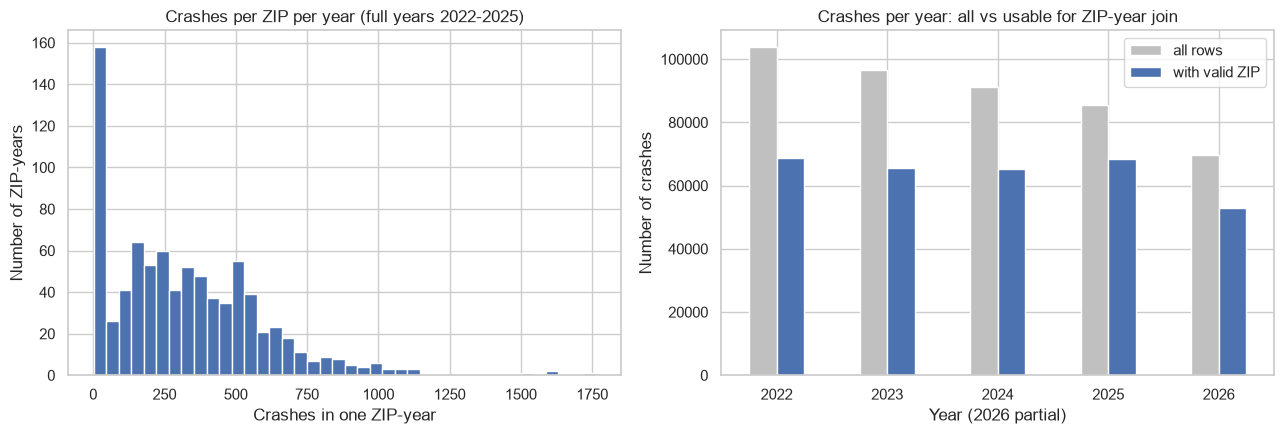

In [25]:
# Visual validation: yearly crash totals still agree with the raw data, and ZIP x year cells look sensible.
valid = clean.dropna(subset=["zip_code"])
cells = valid.groupby(["zip_code", "year"]).size().rename("crashes").reset_index()
print("ZIP x year cells:", len(cells), "| distinct ZIPs:", cells['zip_code'].nunique())
print("crashes kept in ZIP x year (have valid ZIP): {:,} of {:,} ({:.1%})".format(len(valid), len(clean), len(valid) / len(clean)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(cells.loc[cells["year"] < 2026, "crashes"], bins=40, color="#4c72b0")
axes[0].set(title="Crashes per ZIP per year (full years 2022-2025)", xlabel="Crashes in one ZIP-year", ylabel="Number of ZIP-years")
tot = pd.DataFrame({"all rows": clean.groupby("year").size(), "with valid ZIP": valid.groupby("year").size()})
tot.plot(kind="bar", ax=axes[1], color=["#c0c0c0", "#4c72b0"], rot=0)
axes[1].set(title="Crashes per year: all vs usable for ZIP-year join", xlabel="Year (2026 partial)", ylabel="Number of crashes")
plt.tight_layout(); plt.show()

**Reading the validation.** After cleaning, the dtypes match the team standard (`zip_code` string, `year` integer), no duplicates, no placeholder coordinates, no invalid ZIPs. About 72% of crashes carry a valid ZIP and are usable for the ZIP x year join; the right-hand chart shows the usable share is lowest in 2022-2023. Per-ZIP-year counts are right-skewed (a few busy ZIPs, many quiet ones), so the later analysis should compare **ranks or per-month rates**, not assume a normal distribution.

In [26]:
log_df = pd.DataFrame(log)
log_df

,step,rows_affected,decision
0,duplicates on collision_id,0,drop_duplicates (keep first); 0 found in this ...
1,dtype conversion,447156,"dates -> datetime, counts -> int16, added year..."
2,invalid ZIP placeholders,443,"set to missing (10000, 12345)"
3,missing ZIP,126237,kept + flagged (zip_missing); excluded only at...
4,"invalid coordinates (0,0 / outside NYC)",6282,set to missing
5,extreme injury crashes,24,kept + flagged (>=15 injured); no value removed
6,redundant / unused columns,4,"dropped: location, on_street_name, off_street_..."


## 6. Export for the join
The export keeps one row per crash with the agreed shared columns. `data/collisions_step2.csv.gz` is the input for the ZIP x year aggregation (Issa's join notebook). Reading it back with `dtype={"zip_code": str}` is mandatory, or ZIPs turn into floats again.

In [27]:
export_cols = ["collision_id", "crash_date", "crash_time", "year", "month", "hour", "is_partial_year",
               "borough", "zip_code", "zip_missing", "latitude", "longitude"] + num_cols + ["extreme_injury"] + factor_cols + vehicle_cols
clean[export_cols].to_csv(STEP2, index=False, compression="gzip")

back = pd.read_csv(STEP2, dtype={"zip_code": str, "collision_id": str})
assert len(back) == len(clean)
assert back["zip_code"].dropna().str.fullmatch(r"\d{5}").all()
assert back["year"].dtype.kind == "i"
print("Wrote", STEP2, "| rows:", f"{len(back):,}", "| columns:", back.shape[1])
print("size on disk: {:.1f} MB".format(STEP2.stat().st_size / 1e6))

Wrote data\collisions_step2.csv.gz | rows: 447,156 | columns: 31
size on disk: 21.3 MB


## 7. Limitations of this data (carry into the website's story section)
1. **~28% of crashes have no ZIP**, unevenly across years (34% in 2022, 20% in 2025); ZIP-level crash counts are therefore undercounts, most of all for 2022-2023.
2. **No traffic-volume data:** a ZIP with more crashes may simply have more cars and people. We can describe association only, never danger per exposure or causation.
3. **2026 is partial** (data to 2026-10-31); do not compare it with full years.
4. **Severe multi-casualty crashes** (>= 15 injured, flagged `extreme_injury`) can dominate a small ZIP's total; check results with and without them.
5. **"Unspecified" / "Does Not Apply"** dominate the contributing-factor columns; exclude them when ranking factors.
6. Crash records come from police reports: injuries and factors reflect what the officer recorded.

**Handoff to the join:** aggregate with `valid = df.dropna(subset=["zip_code"])` and `groupby(["zip_code", "year"])`: crash count, sum of persons / pedestrian / cyclist injured and killed, and the top contributing factor (excluding the two non-informative values).

## Prompts used
Full log in `AI_PROMPTS.txt` (entries by Ahmed Sanad).

AI-assisted parts of this notebook (Claude): the API pull and cache (section 1), the feasibility check (section 2), the EDA plots (section 3), every cleaning step and its justification text (sections 4.1-4.8), the validation checks (section 5), the export (section 6) and the limitations list (section 7). Ahmed reviews the output and owns the decisions.